<a href="https://colab.research.google.com/github/sangramshitole07/AML/blob/main/AllDecisionTree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris,load_breast_cancer
from sklearn.model_selection import train_test_split,KFold,StratifiedKFold,cross_val_score,GridSearchCV
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import(
    confusion_matrix,
    classification_report,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

In [6]:
iris =load_iris(as_frame=True)
df=iris.frame.copy()
X=df.drop(columns='target')
y=df['target']

print("Shape:",df.shape)
print("Features:",df.columns)
print(df.head())
print(df.duplicated().sum())
print(df.info())
print(df.isnull().sum())

Shape: (150, 5)
Features: Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='object')
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  
1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64


In [7]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.20,random_state=42, stratify=y)



In [10]:
#using entropy
entropy_tree=DecisionTreeClassifier(
    criterion='entropy',
    random_state=42)
entropy_tree.fit(X_train,y_train)
y_pred_entropy=entropy_tree.predict(X_test)
print(classification_report(y_test,y_pred_entropy))
print("Prediction:", y_pred_entropy)
print("Actual Value:",y_test.to_numpy())
print("Accuracy score:", accuracy_score(y_test,y_pred_entropy))
print("Recall score:", recall_score(y_test,y_pred_entropy,average='weighted'))
print("Precision score:", precision_score(y_test,y_pred_entropy,average='weighted'))
print("F1 score:", f1_score(y_test,y_pred_entropy,average='weighted'))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Prediction: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]
Actual Value: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Accuracy score: 0.9333333333333333
Recall score: 0.9333333333333333
Precision score: 0.9333333333333333
F1 score: 0.9333333333333333


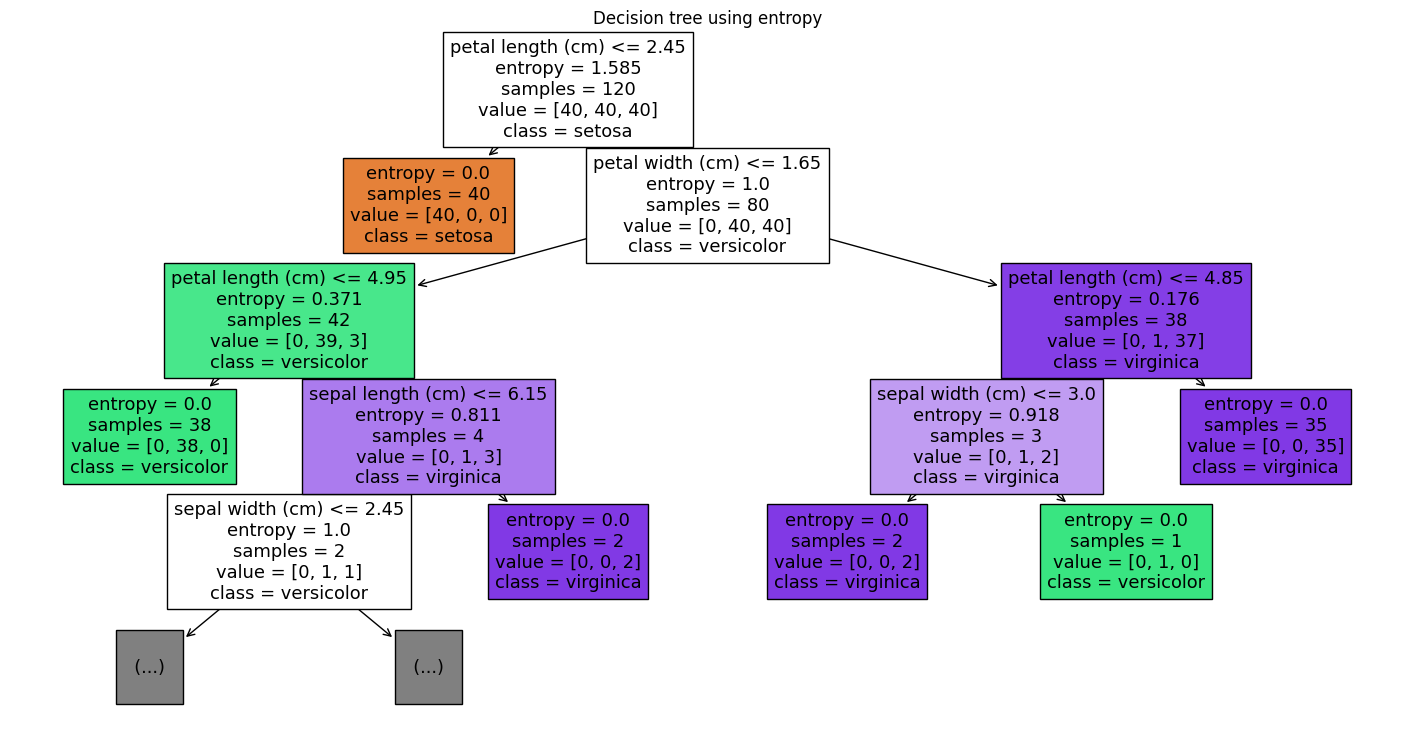

In [20]:
plt.figure(figsize=(18,9))
plot_tree(
    entropy_tree,
    feature_names=X.columns,
    class_names=iris.target_names,
    filled=True,
    #rounded=True,
    max_depth=4
)
plt.title("Decision tree using entropy")
plt.show()

In [22]:
gini_tree=DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)
gini_tree.fit(X_train,y_train)
gini_pred=gini_tree.predict(X_test)
print("gini accuracy :", accuracy_score(y_test,gini_pred))
print("Entropy Acc:",accuracy_score(y_test,y_pred_entropy))
print("Entropy macro F1:",f1_score(y_test,y_pred_entropy,average="macro"))
print("Gini macro F1:",f1_score(y_test,y_pred_entropy,average="macro") )

gini accuracy : 0.9333333333333333
Entropy Acc: 0.9333333333333333
Entropy macro F1: 0.9333333333333332
Gini macro F1: 0.9333333333333332


In [23]:
pruned_tree=DecisionTreeClassifier(
    criterion='entropy',
    min_samples_leaf=2,
    min_samples_split=4,
    random_state=42
)
pruned_tree.fit(X_train,y_train)
pruned_pred=pruned_tree.predict(X_test)
print("pruned accuracy :", accuracy_score(y_test,pruned_pred))
print("Entropy Acc:",accuracy_score(y_test,y_pred_entropy))

pruned accuracy : 0.9333333333333333
Entropy Acc: 0.9333333333333333


In [26]:
# Stratified K-Fold is recommended for classification because it preserves class proportions.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_tree = DecisionTreeClassifier(criterion="entropy", random_state=42)

cv_scores = cross_val_score(cv_tree, X, y, cv=skf, scoring="accuracy")
print("Fold accuracies:", np.round(cv_scores, 3))
print("Mean CV accuracy:", cv_scores.mean())
print("Std CV accuracy:", cv_scores.std())

Fold accuracies: [1.    0.967 0.933 0.967 0.9  ]
Mean CV accuracy: 0.9533333333333335
Std CV accuracy: 0.03399346342395189


In [29]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, None],
    "min_samples_leaf": [1, 2, 3],
    "ccp_alpha": [0.0, 0.001, 0.01]
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="accuracy",

)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", grid.best_score_)
best_tree = grid.best_estimator_
best_pred = best_tree.predict(X_test)
print("Final held-out test accuracy:", accuracy_score(y_test, best_pred))
print("Final held-out macro F1:", f1_score(y_test, best_pred, average="macro"))

Best parameters: {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 3}
Best CV accuracy: 0.9666666666666668
Final held-out test accuracy: 0.9666666666666667
Final held-out macro F1: 0.9665831244778612


In [30]:
new_iris = pd.DataFrame(
    [[5.8, 2.7, 5.1, 1.9]],
    columns=X.columns
)
predicted_class = best_tree.predict(new_iris)[0]
print("Predicted class index:", predicted_class)
print("Predicted species:", iris.target_names[predicted_class])

Predicted class index: 2
Predicted species: virginica


In [33]:
bc = load_breast_cancer(as_frame=True)
bc_df = bc.frame.copy()
X_bc = bc_df.drop(columns="target")
y_bc = bc_df["target"]

print("Shape:", bc_df.shape)
display(bc_df.head())
print("Class counts:")
display(y_bc.value_counts().sort_index())

Xbc_train, Xbc_test, ybc_train, ybc_test = train_test_split(
    X_bc, y_bc, test_size=0.25, random_state=42, stratify=y_bc
)

binary_tree = DecisionTreeClassifier(
    criterion="entropy", max_depth=4, random_state=42
)
binary_tree.fit(Xbc_train, ybc_train)
binary_pred = binary_tree.predict(Xbc_test)

print("Accuracy :", accuracy_score(ybc_test, binary_pred))
print("Precision:", precision_score(ybc_test, binary_pred, zero_division=0))
print("Recall   :", recall_score(ybc_test, binary_pred, zero_division=0))
print("F1       :", f1_score(ybc_test, binary_pred, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(ybc_test, binary_pred))
print(classification_report(ybc_test, binary_pred,
                           target_names=bc.target_names, zero_division=0))

Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Class counts:


,count
target,
0,212
1,357


Accuracy : 0.951048951048951
Precision: 0.9560439560439561
Recall   : 0.9666666666666667
F1       : 0.9613259668508287
Confusion matrix:
[[49  4]
 [ 3 87]]
              precision    recall  f1-score   support

   malignant       0.94      0.92      0.93        53
      benign       0.96      0.97      0.96        90

    accuracy                           0.95       143
   macro avg       0.95      0.95      0.95       143
weighted avg       0.95      0.95      0.95       143

